# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1348 | Val: 323 | Test: 856


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 0.9697 acc 0.524 | val loss 0.8543 acc 0.585 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 0.7438 acc 0.622 | val loss 0.7428 acc 0.659 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.6497 acc 0.687 | val loss 0.8716 acc 0.619


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.6122 acc 0.687 | val loss 0.6572 acc 0.663 *


...

[ResNet-18 (scratch)] Epoch  15/100 | LR: 6.83e-05 | train loss 0.0748 acc 0.967 | val loss 0.9936 acc 0.724


[ResNet-18 (scratch)] Epoch  16/100 | LR: 6.83e-05 | train loss 0.0789 acc 0.967 | val loss 0.9661 acc 0.681


[ResNet-18 (scratch)] Epoch  17/100 | LR: 6.83e-05 | train loss 0.0876 acc 0.963 | val loss 0.8312 acc 0.715


[ResNet-18 (scratch)] Epoch  18/100 | LR: 6.83e-05 | train loss 0.0790 acc 0.963 | val loss 0.9135 acc 0.712


[ResNet-18 (scratch)] Epoch  19/100 | LR: 6.83e-05 | train loss 0.0835 acc 0.963 | val loss 0.8725 acc 0.706

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 19.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5785)


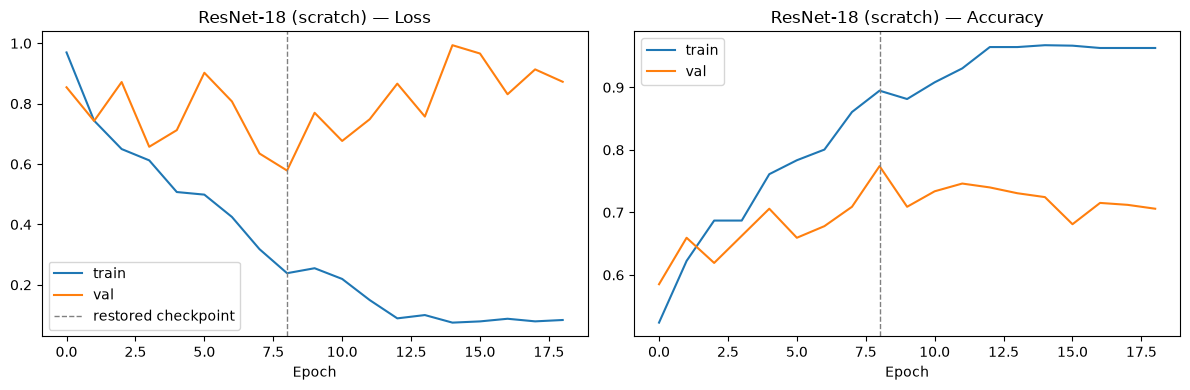

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.664


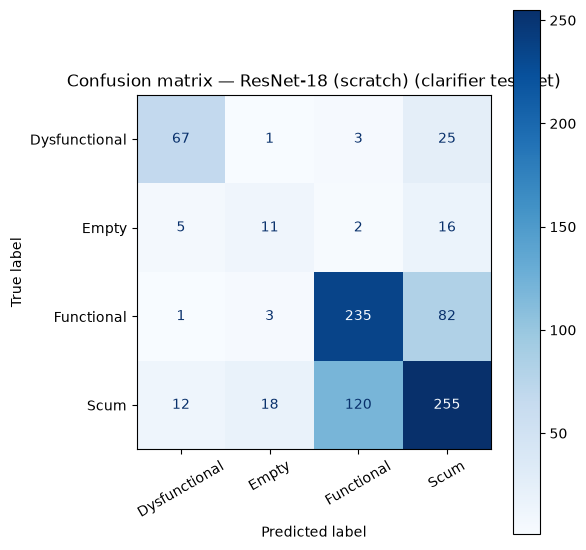

               precision    recall  f1-score   support

Dysfunctional      0.788     0.698     0.740        96
        Empty      0.333     0.324     0.328        34
   Functional      0.653     0.732     0.690       321
         Scum      0.675     0.630     0.651       405

     accuracy                          0.664       856
    macro avg      0.612     0.596     0.603       856
 weighted avg      0.666     0.664     0.663       856



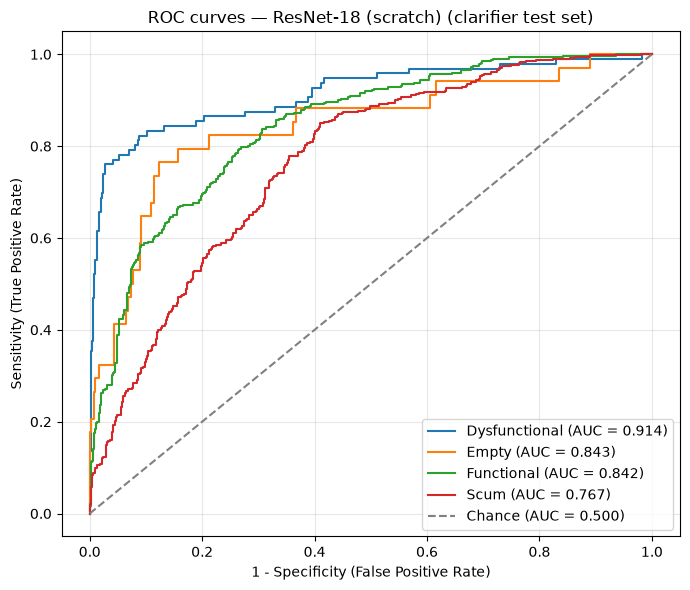

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.914
  Empty          : 0.843
  Functional     : 0.842
  Scum           : 0.767

Mean AUC (over 4/4 classes with test examples): 0.842


(np.float64(0.6635514018691588),
 {'Dysfunctional': 0.9144736842105263,
  'Empty': 0.8434235007871761,
  'Functional': 0.842367601246106,
  'Scum': 0.7667734253100107})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_noaug/results_clarifier_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/clarifier_noaug/clarifier_resnet18_scratch_chronological.pt
